# Sistema de Análise de Irrigação

**Projeto de Ciência de Dados aplicada à agricultura irrigada**

Este notebook/script executa as 13 etapas da checklist do projeto:

1. Carregar os dados de irrigação a partir do CSV;
2. Visualizar a estrutura e as variáveis;
3. Calcular estatísticas descritivas;
4. Criar gráficos de dispersão;
5. Analisar a correlação entre as variáveis;
6. Dividir os dados em treino e teste;
7. Treinar a regressão linear (X = horas, Y = área irrigada por ângulo);
8. Imprimir a equação da reta;
9. Calcular MSE e MAE (e métricas complementares);
10. Comparar valores reais e preditos em gráfico;
11. Calcular e analisar os resíduos;
12. Verificar a normalidade dos resíduos (testes e gráficos);
13. Fazer predições (exemplo: 15 horas de irrigação).

> **Fonte dos dados:** `Arquivos/dados_de_irrigacao.csv`
>
> **Saídas:** `resultados/figuras/`, `resultados/tabelas/` e `resultados/relatorio.md`.
>
> **Como usar:** no notebook, execute as células em ordem (Run All). No script,
> execute `python analise_irrigacao.py` a partir da pasta `Projeto`.

In [ ]:
# =============================================================================
# 0. CONFIGURAÇÃO DO AMBIENTE
# =============================================================================
from pathlib import Path
import sys
import warnings

# Garante que acentos e símbolos não quebrem o console do Windows (cp1252).
# No Jupyter, o ipykernel já gerencia a codificação; não mexemos nela.
if "ipykernel" not in sys.modules:
    for fluxo in (sys.stdout, sys.stderr):
        if hasattr(fluxo, "reconfigure"):
            fluxo.reconfigure(encoding="utf-8", errors="replace")

import numpy as np
import pandas as pd
import matplotlib

# Em script (fora do Jupyter), usa backend sem interface gráfica.
EXECUTANDO_NO_NOTEBOOK = "ipykernel" in sys.modules
if not EXECUTANDO_NO_NOTEBOOK:
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, ScalarFormatter
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)

# Localiza a pasta do projeto tanto no script quanto no notebook.
try:
    BASE_DIR = Path(__file__).resolve().parent
except NameError:
    BASE_DIR = Path.cwd()
    for candidato in [BASE_DIR, *BASE_DIR.parents]:
        if (candidato / "Arquivos" / "dados_de_irrigacao.csv").exists():
            BASE_DIR = candidato
            break

ARQUIVO_DADOS = BASE_DIR / "Arquivos" / "dados_de_irrigacao.csv"
PASTA_RESULTADOS = BASE_DIR / "resultados"
PASTA_FIGURAS = PASTA_RESULTADOS / "figuras"
PASTA_TABELAS = PASTA_RESULTADOS / "tabelas"

for pasta in (PASTA_RESULTADOS, PASTA_FIGURAS, PASTA_TABELAS):
    pasta.mkdir(parents=True, exist_ok=True)

# Paleta e estilo dos gráficos.
VERDE = "#1b7f4d"
VERDE_CLARO = "#7bc96f"
DOURADO = "#e09f3e"
VERMELHO = "#c44536"
CINZA = "#6c757d"

plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.titlesize": 13,
        "axes.titleweight": "bold",
        "axes.labelsize": 10.5,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "grid.linestyle": "--",
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

# `display` existe no Jupyter; no script, usamos print como alternativa.
try:
    display
except NameError:
    def display(obj):
        print(obj)

NOMES = {
    "horas_irrigacao": "Horas de irrigação",
    "area_irrigada": "Área irrigada",
    "area_irrigada_angulo": "Área irrigada por ângulo",
}


# -----------------------------------------------------------------------------
# Funções auxiliares de formatação (padrão brasileiro) e de tabela Markdown.
# -----------------------------------------------------------------------------
def fmt(valor, casas=4):
    """Formata números no padrão brasileiro, com notação científica quando útil."""
    if valor is None:
        return "—"
    if isinstance(valor, (float, np.floating)) and (np.isnan(valor) or np.isinf(valor)):
        return "—"
    if isinstance(valor, (int, np.integer)):
        return f"{int(valor):,}".replace(",", ".")

    valor = float(valor)
    if valor != 0 and (abs(valor) < 10 ** (-casas) or abs(valor) >= 1e6):
        texto = f"{valor:.{casas}e}"
        mantissa, expoente = texto.split("e")
        sobrescritos = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")
        return f"{mantissa.replace('.', ',')} × 10{str(int(expoente)).translate(sobrescritos)}"

    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


def fmt_p(p):
    """Formata p-valores de forma legível."""
    if p is None or (isinstance(p, (float, np.floating)) and np.isnan(p)):
        return "—"
    if p < 0.001:
        return "< 0,001"
    return f"= {fmt(p, 4)}"


def formatar_df(df, casas=4):
    """Cria uma cópia do DataFrame com números formatados para exibição."""
    saida = df.copy()
    for coluna in saida.columns:
        if pd.api.types.is_numeric_dtype(saida[coluna]):
            saida[coluna] = saida[coluna].map(lambda v: fmt(v, casas))
    return saida


def md_table(df, casas=4):
    """Converte um DataFrame em tabela Markdown com números no padrão brasileiro."""
    return formatar_df(df, casas).to_markdown(index=False)


def salvar_csv(df, nome):
    """Salva CSV compatível com Excel em português (; e vírgula decimal)."""
    caminho = PASTA_TABELAS / nome
    df.to_csv(caminho, index=False, sep=";", decimal=",", encoding="utf-8-sig")
    print(f"Tabela salva: {caminho.relative_to(BASE_DIR)}")


def salvar_figura(fig, nome):
    """Salva a figura em PNG e a exibe no notebook."""
    caminho = PASTA_FIGURAS / nome
    fig.savefig(caminho, dpi=160, bbox_inches="tight", facecolor="white")
    if EXECUTANDO_NO_NOTEBOOK:
        plt.show()
    plt.close(fig)
    print(f"Figura salva: {caminho.relative_to(BASE_DIR)}")


def formatar_eixo_milhar(valor, _posicao):
    return f"{valor:,.0f}".replace(",", ".")


print("Ambiente configurado.")
print(f"Pasta do projeto: {BASE_DIR}")
print(f"Arquivo de dados: {ARQUIVO_DADOS}")

## 1. Carregamento dos dados

O arquivo é lido com codificação UTF-8 (com BOM) e os nomes das colunas são
normalizados para facilitar o código. Em seguida, verificamos dimensões,
tipos, valores ausentes, duplicatas e integridade numérica.

In [2]:
if not ARQUIVO_DADOS.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {ARQUIVO_DADOS}")

df = pd.read_csv(ARQUIVO_DADOS, encoding="utf-8-sig")

# Renomeia por posição para garantir nomes estáveis no código.
if df.shape[1] != 3:
    raise ValueError(
        f"Esperadas 3 colunas, mas o arquivo possui {df.shape[1]}: {list(df.columns)}"
    )
df.columns = ["horas_irrigacao", "area_irrigada", "area_irrigada_angulo"]

print(f"Formato do conjunto: {df.shape[0]} linhas × {df.shape[1]} colunas")
print("\nPrimeiras 5 linhas:")
display(df.head())
print("\nÚltimas 5 linhas:")
display(df.tail())
print("\nTipos de dados:")
display(df.dtypes.to_frame("tipo"))

qualidade = pd.DataFrame(
    {
        "variavel": [NOMES[c] for c in df.columns],
        "tipo": [str(t) for t in df.dtypes],
        "valores_ausentes": df.isna().sum().values,
        "valores_unicos": df.nunique().values,
        "minimo": df.min().values,
        "maximo": df.max().values,
    }
)
print("\nQualidade dos dados:")
display(qualidade)

duplicadas = int(df.duplicated().sum())
ausentes_total = int(df.isna().sum().sum())
negativos = int((df < 0).sum().sum())

print(f"Linhas duplicadas: {duplicadas}")
print(f"Valores ausentes: {ausentes_total}")
print(f"Valores negativos: {negativos}")

if ausentes_total == 0 and duplicadas == 0 and negativos == 0:
    print("\n[OK] Base íntegra: sem ausentes, duplicatas ou valores negativos.")
else:
    print("\n[ATENÇÃO] A base precisa de tratamento antes da modelagem.")

salvar_csv(qualidade, "qualidade_dados.csv")

Formato do conjunto: 299 linhas × 3 colunas

Primeiras 5 linhas:


,horas_irrigacao,area_irrigada,area_irrigada_angulo
0,1,100,66.666667
1,2,200,133.333333
2,3,300,200.000000
3,4,400,266.666667
4,5,500,333.333333



Últimas 5 linhas:


,horas_irrigacao,area_irrigada,area_irrigada_angulo
294,295,29500,19666.666667
295,296,29600,19733.333333
296,297,29700,19800.000000
297,298,29800,19866.666667
298,299,29900,19933.333333



Tipos de dados:


,tipo
horas_irrigacao,int64
area_irrigada,int64
area_irrigada_angulo,float64



Qualidade dos dados:


,variavel,tipo,valores_ausentes,valores_unicos,minimo,maximo
0,Horas de irrigação,int64,0,299,1.000000,299.000000
1,Área irrigada,int64,0,299,100.000000,29900.000000
2,Área irrigada por ângulo,float64,0,299,66.666667,19933.333333


Linhas duplicadas: 0
Valores ausentes: 0
Valores negativos: 0

[OK] Base íntegra: sem ausentes, duplicatas ou valores negativos.
Tabela salva: resultados\tabelas\qualidade_dados.csv


## 2. Estatísticas descritivas

Calculamos medidas de tendência central, dispersão e forma para as três
variáveis. O coeficiente de variação (CV) permite comparar a dispersão
relativa entre variáveis com escalas diferentes.

In [3]:
stats_df = df.describe().T.rename(
    columns={
        "count": "n",
        "mean": "media",
        "std": "desvio_padrao",
        "min": "minimo",
        "25%": "q1",
        "50%": "mediana",
        "75%": "q3",
        "max": "maximo",
    }
)
stats_df["n"] = stats_df["n"].astype(int)
stats_df["coef_variacao_pct"] = df.std() / df.mean() * 100
stats_df["assimetria"] = df.skew()
stats_df["curtose"] = df.kurt()
stats_df = stats_df[
    [
        "n",
        "media",
        "desvio_padrao",
        "minimo",
        "q1",
        "mediana",
        "q3",
        "maximo",
        "coef_variacao_pct",
        "assimetria",
        "curtose",
    ]
]
stats_df = stats_df.rename(index=NOMES)
stats_df.index.name = "variavel"

print("Estatísticas descritivas:")
display(stats_df)
salvar_csv(stats_df.reset_index(), "estatisticas_descritivas.csv")

Estatísticas descritivas:


,n,media,desvio_padrao,minimo,q1,mediana,q3,maximo,coef_variacao_pct,assimetria,curtose
variavel,,,,,,,,,,,
Horas de irrigação,299,150.0,86.458082,1.000000,75.500000,150.0,224.500000,299.000000,57.638722,0.000000e+00,-1.2
Área irrigada,299,15000.0,8645.808233,100.000000,7550.000000,15000.0,22450.000000,29900.000000,57.638722,0.000000e+00,-1.2
Área irrigada por ângulo,299,10000.0,5763.872155,66.666667,5033.333333,10000.0,14966.666667,19933.333333,57.638722,1.587224e-15,-1.2


Tabela salva: resultados\tabelas\estatisticas_descritivas.csv


## 3. Visualização da estrutura e gráficos de dispersão

Os gráficos de dispersão mostram a relação entre as horas de irrigação e as
áreas. Também incluímos a relação entre as duas medidas de área, que ajuda a
entender a estrutura dos dados.

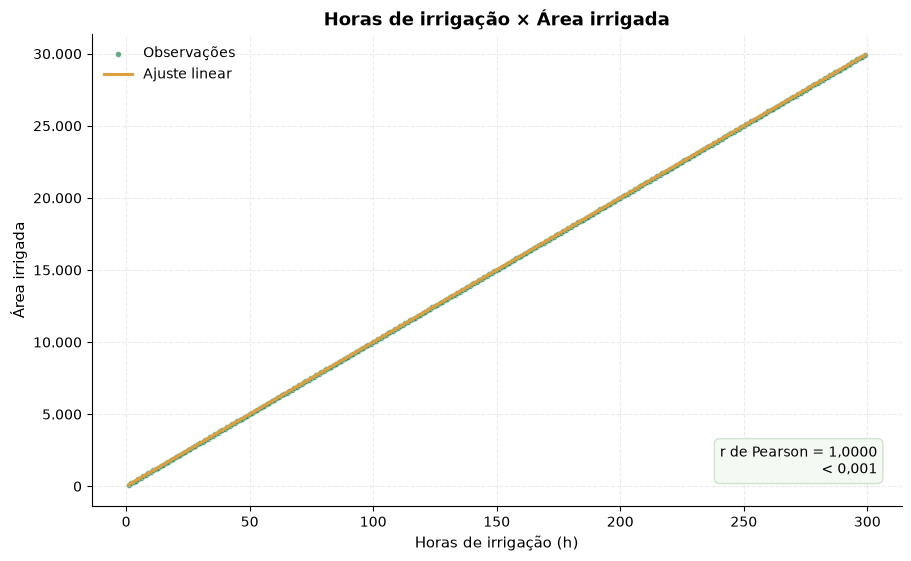

Figura salva: resultados\figuras\01_dispersao_horas_area.png


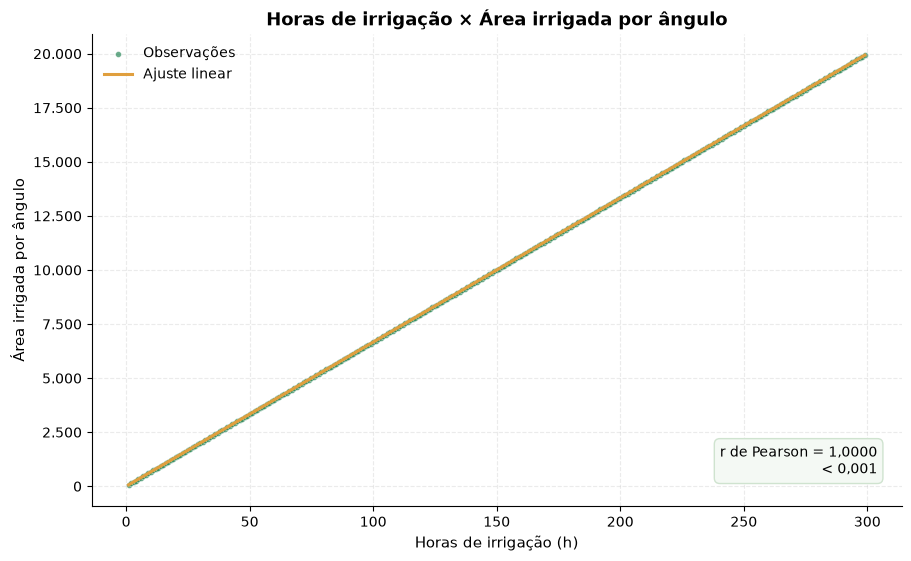

Figura salva: resultados\figuras\02_dispersao_horas_area_angulo.png


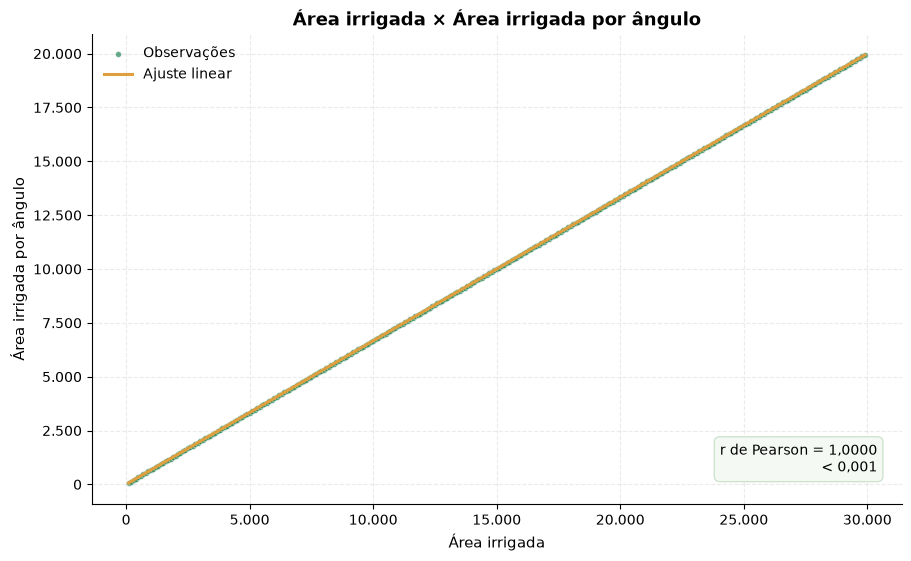

Figura salva: resultados\figuras\03_dispersao_area_area_angulo.png


In [4]:
# Figura 1 — Horas de irrigação × Área irrigada
x = df["horas_irrigacao"].to_numpy()
y_area = df["area_irrigada"].to_numpy()
r_area, p_area = stats.pearsonr(x, y_area)
coef_area = np.polyfit(x, y_area, 1)
x_linha = np.linspace(x.min(), x.max(), 200)

fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
ax.scatter(
    x, y_area, s=18, color=VERDE, alpha=0.65, edgecolor="white", linewidth=0.4,
    label="Observações",
)
ax.plot(x_linha, np.polyval(coef_area, x_linha), color=DOURADO, lw=2.2, label="Ajuste linear")
ax.set_title("Horas de irrigação × Área irrigada")
ax.set_xlabel("Horas de irrigação (h)")
ax.set_ylabel("Área irrigada")
ax.yaxis.set_major_formatter(FuncFormatter(formatar_eixo_milhar))
ax.legend(loc="upper left", frameon=False)
ax.text(
    0.97, 0.06,
    f"r de Pearson = {fmt(r_area, 4)}\n{fmt_p(p_area)}",
    transform=ax.transAxes, ha="right", va="bottom", fontsize=10,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#f4f9f4", edgecolor="#cfe3cf"),
)
salvar_figura(fig, "01_dispersao_horas_area.png")

# Figura 2 — Horas de irrigação × Área irrigada por ângulo
y_angulo = df["area_irrigada_angulo"].to_numpy()
r_angulo, p_angulo = stats.pearsonr(x, y_angulo)
coef_angulo = np.polyfit(x, y_angulo, 1)

fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
ax.scatter(
    x, y_angulo, s=18, color=VERDE, alpha=0.65, edgecolor="white", linewidth=0.4,
    label="Observações",
)
ax.plot(x_linha, np.polyval(coef_angulo, x_linha), color=DOURADO, lw=2.2, label="Ajuste linear")
ax.set_title("Horas de irrigação × Área irrigada por ângulo")
ax.set_xlabel("Horas de irrigação (h)")
ax.set_ylabel("Área irrigada por ângulo")
ax.yaxis.set_major_formatter(FuncFormatter(formatar_eixo_milhar))
ax.legend(loc="upper left", frameon=False)
ax.text(
    0.97, 0.06,
    f"r de Pearson = {fmt(r_angulo, 4)}\n{fmt_p(p_angulo)}",
    transform=ax.transAxes, ha="right", va="bottom", fontsize=10,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#f4f9f4", edgecolor="#cfe3cf"),
)
salvar_figura(fig, "02_dispersao_horas_area_angulo.png")

# Figura 3 — Área irrigada × Área irrigada por ângulo
r_areas, p_areas = stats.pearsonr(y_area, y_angulo)
coef_areas = np.polyfit(y_area, y_angulo, 1)
x_areas_linha = np.linspace(y_area.min(), y_area.max(), 200)

fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
ax.scatter(
    y_area, y_angulo, s=18, color=VERDE, alpha=0.65, edgecolor="white", linewidth=0.4,
    label="Observações",
)
ax.plot(
    x_areas_linha, np.polyval(coef_areas, x_areas_linha),
    color=DOURADO, lw=2.2, label="Ajuste linear",
)
ax.set_title("Área irrigada × Área irrigada por ângulo")
ax.set_xlabel("Área irrigada")
ax.set_ylabel("Área irrigada por ângulo")
ax.xaxis.set_major_formatter(FuncFormatter(formatar_eixo_milhar))
ax.yaxis.set_major_formatter(FuncFormatter(formatar_eixo_milhar))
ax.legend(loc="upper left", frameon=False)
ax.text(
    0.97, 0.06,
    f"r de Pearson = {fmt(r_areas, 4)}\n{fmt_p(p_areas)}",
    transform=ax.transAxes, ha="right", va="bottom", fontsize=10,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#f4f9f4", edgecolor="#cfe3cf"),
)
salvar_figura(fig, "03_dispersao_area_area_angulo.png")

## 4. Análise de correlação

Calculamos a correlação de Pearson (relação linear) e a de Spearman (relação
monotônica). Valores próximos de +1 indicam associação linear positiva forte.

Correlação de Pearson:


,Horas de irrigação,Área irrigada,Área irrigada por ângulo
Horas de irrigação,1.0,1.0,1.0
Área irrigada,1.0,1.0,1.0
Área irrigada por ângulo,1.0,1.0,1.0



Correlação de Spearman:


,Horas de irrigação,Área irrigada,Área irrigada por ângulo
Horas de irrigação,1.0,1.0,1.0
Área irrigada,1.0,1.0,1.0
Área irrigada por ângulo,1.0,1.0,1.0


Tabela salva: resultados\tabelas\correlacao_pearson.csv
Tabela salva: resultados\tabelas\correlacao_spearman.csv


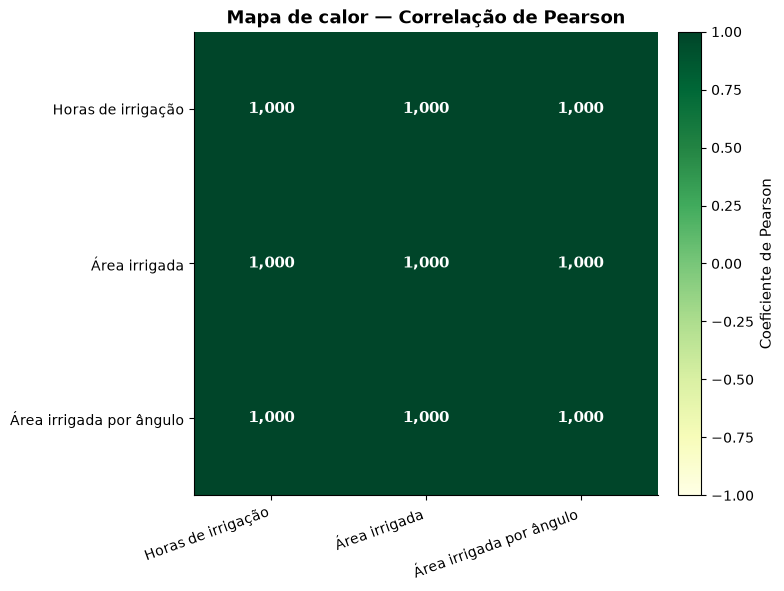

Figura salva: resultados\figuras\04_mapa_calor_correlacao.png


In [5]:
corr_pearson = df.corr(method="pearson")
corr_spearman = df.corr(method="spearman")

print("Correlação de Pearson:")
display(corr_pearson.rename(index=NOMES, columns=NOMES))
print("\nCorrelação de Spearman:")
display(corr_spearman.rename(index=NOMES, columns=NOMES))

salvar_csv(
    corr_pearson.rename(index=NOMES, columns=NOMES).reset_index().rename(
        columns={"index": "variavel"}
    ),
    "correlacao_pearson.csv",
)
salvar_csv(
    corr_spearman.rename(index=NOMES, columns=NOMES).reset_index().rename(
        columns={"index": "variavel"}
    ),
    "correlacao_spearman.csv",
)

# Mapa de calor da correlação de Pearson.
fig, ax = plt.subplots(figsize=(7.5, 5.8), constrained_layout=True)
imagem = ax.imshow(corr_pearson.to_numpy(), cmap="YlGn", vmin=-1, vmax=1)
rotulos = [NOMES[c] for c in corr_pearson.columns]
ax.set_xticks(range(len(rotulos)), rotulos, rotation=20, ha="right")
ax.set_yticks(range(len(rotulos)), rotulos)
ax.set_title("Mapa de calor — Correlação de Pearson")
ax.grid(False)

for i in range(len(rotulos)):
    for j in range(len(rotulos)):
        valor = corr_pearson.iloc[i, j]
        ax.text(
            j, i, fmt(valor, 3), ha="center", va="center",
            color="white" if abs(valor) > 0.6 else "#1f2d1f",
            fontsize=11, fontweight="bold",
        )

fig.colorbar(imagem, ax=ax, fraction=0.046, pad=0.04, label="Coeficiente de Pearson")
salvar_figura(fig, "04_mapa_calor_correlacao.png")

## 5. Divisão em treino e teste

Usamos 80% dos registros para treino e 20% para teste, com `random_state=42`
para garantir reprodutibilidade. A divisão é aleatória simples.

In [6]:
X = df[["horas_irrigacao"]]
y = df["area_irrigada_angulo"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42, shuffle=True
)

print(f"Treino: {X_treino.shape[0]} registros ({X_treino.shape[0] / len(df):.0%})")
print(f"Teste:  {X_teste.shape[0]} registros ({X_teste.shape[0] / len(df):.0%})")

divisao = pd.DataFrame(
    {
        "indice_original": df.index,
        "conjunto": np.where(df.index.isin(X_treino.index), "treino", "teste"),
    }
)
salvar_csv(divisao, "divisao_treino_teste.csv")

Treino: 239 registros (80%)
Teste:  60 registros (20%)
Tabela salva: resultados\tabelas\divisao_treino_teste.csv


## 6. Treinamento do modelo de regressão linear

O modelo é `Y = a·X + b`, em que:
- **X:** horas de irrigação;
- **Y:** área irrigada por ângulo.

In [7]:
modelo = LinearRegression()
modelo.fit(X_treino, y_treino)

coeficiente = float(modelo.coef_[0])
intercepto = float(modelo.intercept_)
r2_treino = float(modelo.score(X_treino, y_treino))
r2_teste = float(modelo.score(X_teste, y_teste))

equacao = (
    f"Área irrigada por ângulo = {fmt(coeficiente, 4)} × Horas de irrigação "
    f"+ ({fmt(intercepto, 6)})"
)

print("Modelo treinado com sucesso.")
print(f"Coeficiente angular (a): {fmt(coeficiente, 6)}")
print(f"Intercepto (b):          {fmt(intercepto, 6)}")
print(f"R² treino:               {fmt(r2_treino, 6)}")
print(f"R² teste:                {fmt(r2_teste, 6)}")
print("\nEquação da reta:")
print(equacao)

with open(PASTA_TABELAS / "resumo_modelo.txt", "w", encoding="utf-8") as arquivo:
    arquivo.write("RESUMO DO MODELO DE REGRESSÃO LINEAR\n")
    arquivo.write("=" * 45 + "\n")
    arquivo.write(f"Variável independente (X): horas_irrigacao\n")
    arquivo.write(f"Variável dependente (Y):   area_irrigada_angulo\n")
    arquivo.write(f"Registros de treino:       {X_treino.shape[0]}\n")
    arquivo.write(f"Registros de teste:        {X_teste.shape[0]}\n")
    arquivo.write(f"Coeficiente angular:       {coeficiente:.10f}\n")
    arquivo.write(f"Intercepto:                {intercepto:.10e}\n")
    arquivo.write(f"R² treino:                 {r2_treino:.10f}\n")
    arquivo.write(f"R² teste:                  {r2_teste:.10f}\n")
    arquivo.write(f"Equação:                   {equacao}\n")

print(f"Resumo salvo: {(PASTA_TABELAS / 'resumo_modelo.txt').relative_to(BASE_DIR)}")

Modelo treinado com sucesso.
Coeficiente angular (a): 66,666667
Intercepto (b):          1,818989 × 10⁻¹²
R² treino:               1,000000
R² teste:                1,000000

Equação da reta:
Área irrigada por ângulo = 66,6667 × Horas de irrigação + (1,818989 × 10⁻¹²)
Resumo salvo: resultados\tabelas\resumo_modelo.txt


## 7. Avaliação do modelo (MSE, MAE e métricas complementares)

- **MSE:** erro quadrático médio — penaliza erros grandes;
- **MAE:** erro absoluto médio — mesma unidade de Y;
- **RMSE:** raiz do MSE — também na unidade de Y;
- **R²:** proporção da variância de Y explicada pelo modelo;
- **MAPE:** erro percentual absoluto médio.

In [8]:
y_pred = modelo.predict(X_teste)
residuos = y_teste.to_numpy() - y_pred

mse = float(mean_squared_error(y_teste, y_pred))
mae = float(mean_absolute_error(y_teste, y_pred))
rmse = float(np.sqrt(mse))
r2 = float(r2_score(y_teste, y_pred))
mape = float(mean_absolute_percentage_error(y_teste, y_pred) * 100)
erro_maximo = float(np.max(np.abs(residuos)))

metricas = pd.DataFrame(
    {
        "metrica": ["MSE", "MAE", "RMSE", "R²", "MAPE (%)", "Erro absoluto máximo"],
        "valor": [mse, mae, rmse, r2, mape, erro_maximo],
        "descricao": [
            "Erro quadrático médio",
            "Erro absoluto médio",
            "Raiz do erro quadrático médio",
            "Coeficiente de determinação",
            "Erro percentual absoluto médio",
            "Maior erro absoluto no conjunto de teste",
        ],
    }
)

print("Métricas de desempenho no conjunto de teste:")
display(metricas)
salvar_csv(metricas, "metricas_desempenho.csv")

Métricas de desempenho no conjunto de teste:


,metrica,valor,descricao
0,MSE,6.894249e-24,Erro quadrático médio
1,MAE,2.431004e-12,Erro absoluto médio
2,RMSE,2.625690e-12,Raiz do erro quadrático médio
3,R²,1.000000e+00,Coeficiente de determinação
4,MAPE (%),5.312405e-14,Erro percentual absoluto médio
5,Erro absoluto máximo,3.637979e-12,Maior erro absoluto no conjunto de teste


Tabela salva: resultados\tabelas\metricas_desempenho.csv


## 8. Valores reais versus preditos

Quanto mais próximos os pontos estiverem da linha ideal `y = x`, melhor o
ajuste. Também exibimos a reta do modelo e o R² no conjunto de teste.

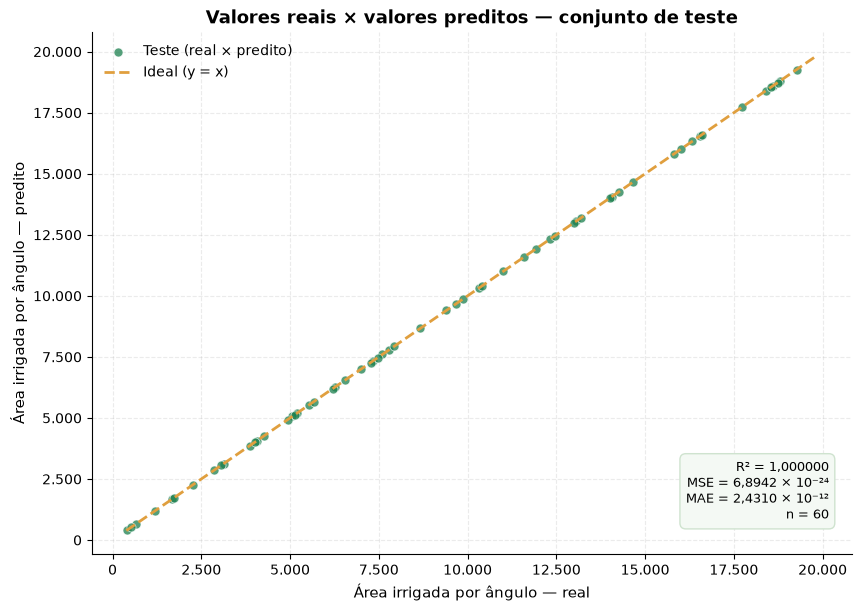

Figura salva: resultados\figuras\05_reais_vs_preditos.png


In [9]:
fig, ax = plt.subplots(figsize=(8.5, 6), constrained_layout=True)
ax.scatter(
    y_teste, y_pred, s=42, color=VERDE, alpha=0.75, edgecolor="white",
    linewidth=0.6, label="Teste (real × predito)", zorder=3,
)

limites = [
    min(float(y_teste.min()), float(y_pred.min())) * 0.97,
    max(float(y_teste.max()), float(y_pred.max())) * 1.03,
]
ax.plot(limites, limites, "--", color=DOURADO, lw=2, label="Ideal (y = x)", zorder=4)

ax.set_title("Valores reais × valores preditos — conjunto de teste")
ax.set_xlabel("Área irrigada por ângulo — real")
ax.set_ylabel("Área irrigada por ângulo — predito")
ax.xaxis.set_major_formatter(FuncFormatter(formatar_eixo_milhar))
ax.yaxis.set_major_formatter(FuncFormatter(formatar_eixo_milhar))
ax.legend(loc="upper left", frameon=False)
ax.text(
    0.97, 0.06,
    f"R² = {fmt(r2, 6)}\nMSE = {fmt(mse, 4)}\nMAE = {fmt(mae, 4)}\nn = {len(y_teste)}",
    transform=ax.transAxes, ha="right", va="bottom", fontsize=9.5,
    bbox=dict(boxstyle="round,pad=0.45", facecolor="#f4f9f4", edgecolor="#cfe3cf"),
)
salvar_figura(fig, "05_reais_vs_preditos.png")

## 9. Análise dos resíduos

Resíduo = valor real − valor predito. Um bom modelo deve apresentar resíduos
sem padrão sistemático, centrados em zero e com dispersão aproximadamente
constante. Salvamos a tabela completa para auditoria.

Tabela salva: resultados\tabelas\residuos_teste.csv
Resumo dos resíduos:


,metrica,valor
0,Média dos resíduos,-2.431004e-12
1,Desvio-padrão dos resíduos,1.000578e-12
2,Resíduo mínimo,-3.637979e-12
3,Resíduo máximo,0.000000e+00
4,Soma dos resíduos,-1.458602e-10
5,Amplitude,3.637979e-12


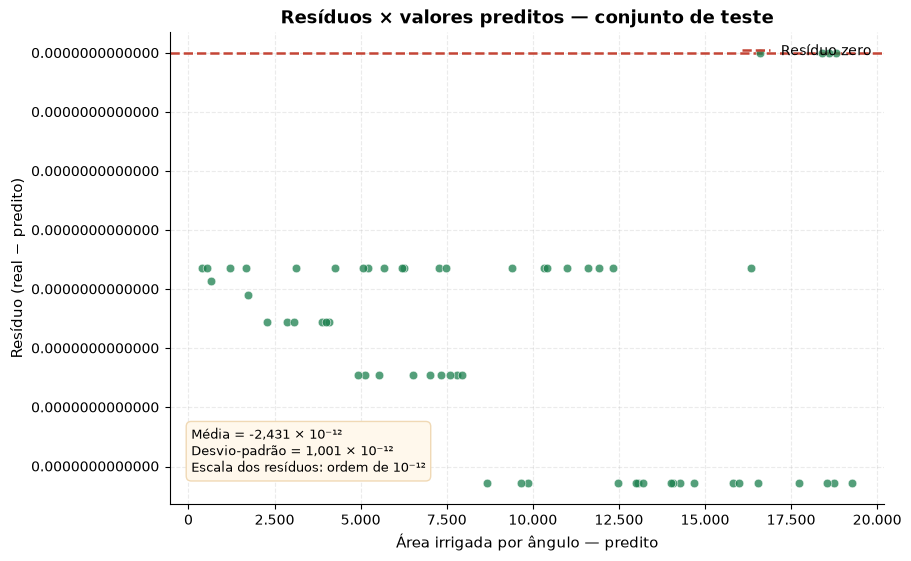

Figura salva: resultados\figuras\06_residuos_vs_preditos.png


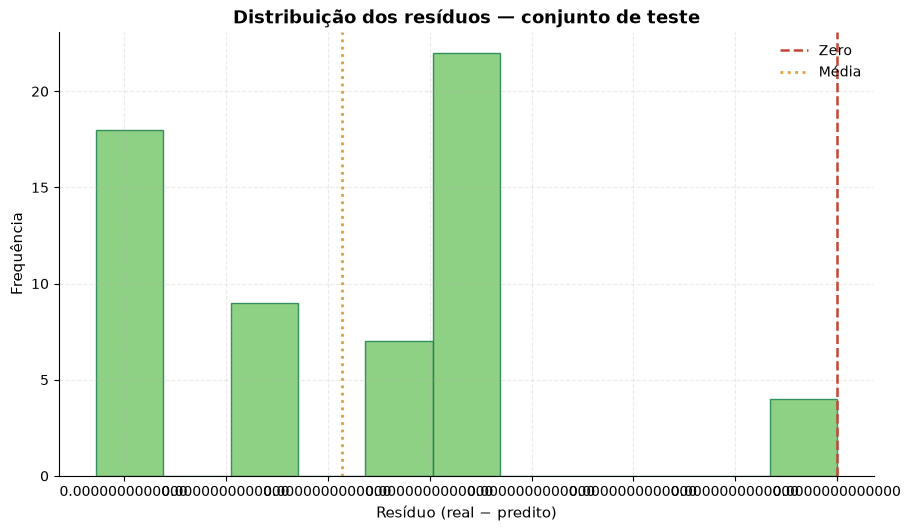

Figura salva: resultados\figuras\07_histograma_residuos.png


In [10]:
tabela_residuos = pd.DataFrame(
    {
        "indice_original": y_teste.index,
        "horas_irrigacao": X_teste["horas_irrigacao"].to_numpy(),
        "valor_real": y_teste.to_numpy(),
        "valor_predito": y_pred,
        "residuo": residuos,
    }
)
salvar_csv(tabela_residuos, "residuos_teste.csv")

resumo_residuos = pd.DataFrame(
    {
        "metrica": [
            "Média dos resíduos",
            "Desvio-padrão dos resíduos",
            "Resíduo mínimo",
            "Resíduo máximo",
            "Soma dos resíduos",
            "Amplitude",
        ],
        "valor": [
            float(np.mean(residuos)),
            float(np.std(residuos, ddof=1)),
            float(np.min(residuos)),
            float(np.max(residuos)),
            float(np.sum(residuos)),
            float(np.ptp(residuos)),
        ],
    }
)
print("Resumo dos resíduos:")
display(resumo_residuos)

# Figura 6 — Resíduos × valores preditos
fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
ax.scatter(
    y_pred, residuos, s=38, color=VERDE, alpha=0.75, edgecolor="white",
    linewidth=0.5, zorder=3,
)
ax.axhline(0, color=VERMELHO, ls="--", lw=1.8, label="Resíduo zero")
ax.set_title("Resíduos × valores preditos — conjunto de teste")
ax.set_xlabel("Área irrigada por ângulo — predito")
ax.set_ylabel("Resíduo (real − predito)")
ax.xaxis.set_major_formatter(FuncFormatter(formatar_eixo_milhar))
ax.yaxis.set_major_formatter(ScalarFormatter(useMathText=True))
ax.ticklabel_format(axis="y", style="sci", scilimits=(-15, -10))
ax.legend(loc="upper right", frameon=False)
ax.text(
    0.03, 0.06,
    f"Média = {fmt(np.mean(residuos), 3)}\nDesvio-padrão = {fmt(np.std(residuos, ddof=1), 3)}\n"
    "Escala dos resíduos: ordem de 10⁻¹²",
    transform=ax.transAxes, ha="left", va="bottom", fontsize=9,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#fff8ec", edgecolor="#f0d9b5"),
)
salvar_figura(fig, "06_residuos_vs_preditos.png")

# Figura 7 — Distribuição dos resíduos
fig, ax = plt.subplots(figsize=(9, 5.2), constrained_layout=True)
bins = np.linspace(float(np.min(residuos)), float(np.max(residuos)), 12)
if np.ptp(residuos) == 0:
    bins = 10
ax.hist(residuos, bins=bins, color=VERDE_CLARO, edgecolor=VERDE, alpha=0.85)
ax.axvline(0, color=VERMELHO, ls="--", lw=1.8, label="Zero")
ax.axvline(float(np.mean(residuos)), color=DOURADO, ls=":", lw=2, label="Média")
ax.set_title("Distribuição dos resíduos — conjunto de teste")
ax.set_xlabel("Resíduo (real − predito)")
ax.set_ylabel("Frequência")
ax.xaxis.set_major_formatter(ScalarFormatter(useMathText=True))
ax.ticklabel_format(axis="x", style="sci", scilimits=(-15, -10))
ax.legend(loc="upper right", frameon=False)
salvar_figura(fig, "07_histograma_residuos.png")

## 10. Normalidade dos resíduos

Aplicamos três testes com hipótese nula (H₀) de que os resíduos seguem uma
distribuição normal:

- **Shapiro-Wilk:** bom para amostras pequenas/médias;
- **D'Agostino-Pearson:** baseado em assimetria e curtose;
- **Jarque-Bera:** também baseado em assimetria e curtose.

Complementamos com um gráfico Q-Q. **Atenção:** como os resíduos são da ordem
de 10⁻¹² (ruído numérico), os testes perdem sentido prático; a interpretação
é discutida no relatório.

Testes de normalidade dos resíduos (α = 0,05):


,teste,estatistica,p_valor,decisao
0,Shapiro-Wilk,0.843705,0.000002,Rejeita H₀ (não normal)
1,D'Agostino-Pearson,3.357250,0.186630,Não rejeita H₀ (compatível com normal)
2,Jarque-Bera,2.757477,0.251896,Não rejeita H₀ (compatível com normal)


Tabela salva: resultados\tabelas\testes_normalidade.csv


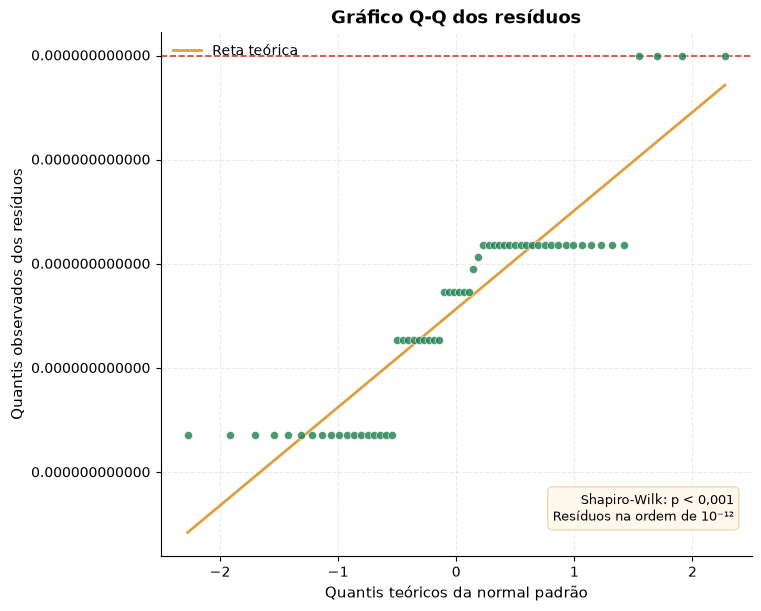

Figura salva: resultados\figuras\08_qq_plot_residuos.png


In [11]:
def executar_testes_normalidade(res):
    """Executa testes de normalidade e devolve uma tabela padronizada."""
    resultados = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            s = stats.shapiro(res)
            resultados.append(("Shapiro-Wilk", float(s.statistic), float(s.pvalue)))
        except Exception as erro:
            resultados.append(("Shapiro-Wilk", np.nan, np.nan))
            print(f"Shapiro-Wilk não pôde ser calculado: {erro}")

        try:
            s = stats.normaltest(res)
            resultados.append(("D'Agostino-Pearson", float(s.statistic), float(s.pvalue)))
        except Exception as erro:
            resultados.append(("D'Agostino-Pearson", np.nan, np.nan))
            print(f"D'Agostino-Pearson não pôde ser calculado: {erro}")

        try:
            s = stats.jarque_bera(res)
            resultados.append(("Jarque-Bera", float(s.statistic), float(s.pvalue)))
        except Exception as erro:
            resultados.append(("Jarque-Bera", np.nan, np.nan))
            print(f"Jarque-Bera não pôde ser calculado: {erro}")

    tabela = pd.DataFrame(resultados, columns=["teste", "estatistica", "p_valor"])
    tabela["decisao"] = tabela["p_valor"].apply(
        lambda p: "Não avaliável"
        if pd.isna(p)
        else ("Rejeita H₀ (não normal)" if p < 0.05 else "Não rejeita H₀ (compatível com normal)")
    )
    return tabela


testes_normalidade = executar_testes_normalidade(residuos)
print("Testes de normalidade dos resíduos (α = 0,05):")
display(testes_normalidade)
salvar_csv(testes_normalidade, "testes_normalidade.csv")

# Figura 8 — Gráfico Q-Q
fig, ax = plt.subplots(figsize=(7.5, 6), constrained_layout=True)
(osm, osr), (inclinacao, intercepto_qq, r_qq) = stats.probplot(residuos, dist="norm")
ax.scatter(osm, osr, s=34, color=VERDE, alpha=0.8, edgecolor="white", linewidth=0.5, zorder=3)
ax.plot(osm, inclinacao * np.asarray(osm) + intercepto_qq, color=DOURADO, lw=2, label="Reta teórica")
ax.axhline(0, color=VERMELHO, ls="--", lw=1.2)
ax.set_title("Gráfico Q-Q dos resíduos")
ax.set_xlabel("Quantis teóricos da normal padrão")
ax.set_ylabel("Quantis observados dos resíduos")
ax.yaxis.set_major_formatter(ScalarFormatter(useMathText=True))
ax.ticklabel_format(axis="y", style="sci", scilimits=(-15, -10))
ax.legend(loc="upper left", frameon=False)
p_shapiro = float(testes_normalidade.loc[testes_normalidade["teste"] == "Shapiro-Wilk", "p_valor"].iloc[0])
ax.text(
    0.97, 0.06,
    f"Shapiro-Wilk: p {fmt_p(p_shapiro)}\nResíduos na ordem de 10⁻¹²",
    transform=ax.transAxes, ha="right", va="bottom", fontsize=9,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#fff8ec", edgecolor="#f0d9b5"),
)
salvar_figura(fig, "08_qq_plot_residuos.png")

## 11. Predições com o modelo

Além do exemplo solicitado (15 horas), geramos previsões para alguns horários
de interesse operacional. Como o modelo é linear e exato nessa base, os
valores seguem exatamente a reta ajustada.

Predição para 15 horas de irrigação:
Área irrigada por ângulo prevista = 1.000,00

Outras previsões:


,horas_irrigacao,area_angulo_prevista,destaque
0,10,666.6667,
1,15,1000.0000,exemplo da checklist
2,20,1333.3333,
3,24,1600.0000,
4,48,3200.0000,


Tabela salva: resultados\tabelas\previsoes.csv


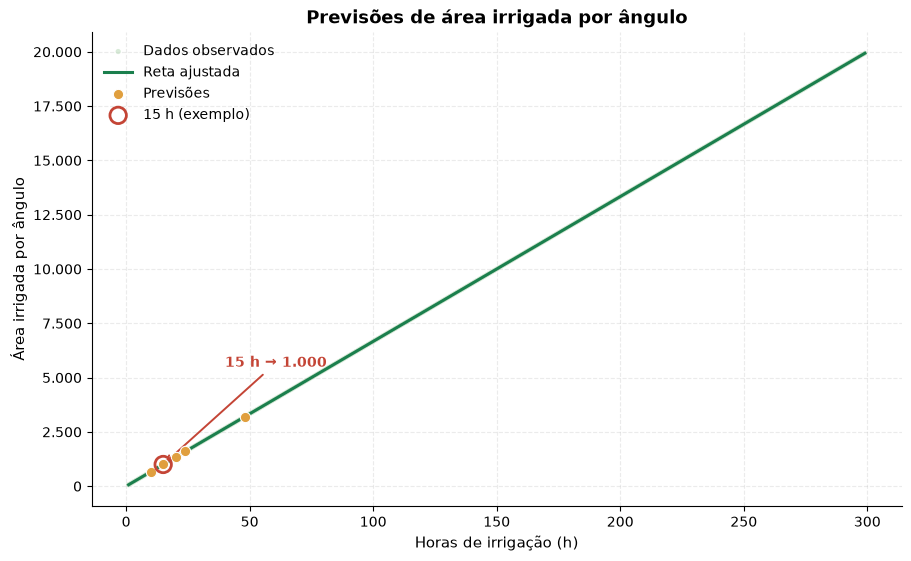

Figura salva: resultados\figuras\09_predicoes.png


In [12]:
horas_exemplo = 15.0
previsao_15 = round(
    float(modelo.predict(pd.DataFrame({"horas_irrigacao": [horas_exemplo]}))[0]), 4
)

horas_previstas = [10, 15, 20, 24, 48]
previsoes = pd.DataFrame({"horas_irrigacao": horas_previstas})
previsoes["area_angulo_prevista"] = np.round(
    modelo.predict(previsoes[["horas_irrigacao"]]), 4
)
previsoes["destaque"] = np.where(
    previsoes["horas_irrigacao"] == horas_exemplo, "exemplo da checklist", ""
)

print(f"Predição para {fmt(horas_exemplo, 0)} horas de irrigação:")
print(f"Área irrigada por ângulo prevista = {fmt(previsao_15, 2)}")
print("\nOutras previsões:")
display(previsoes)
salvar_csv(previsoes, "previsoes.csv")

# Figura 9 — Predições sobre a reta ajustada
fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
ax.scatter(
    df["horas_irrigacao"], df["area_irrigada_angulo"], s=14, color="#b9d9b9",
    alpha=0.55, edgecolor="none", label="Dados observados",
)
ax.plot(
    x_linha, modelo.predict(pd.DataFrame({"horas_irrigacao": x_linha})),
    color=VERDE, lw=2.2, label="Reta ajustada",
)
ax.scatter(
    previsoes["horas_irrigacao"], previsoes["area_angulo_prevista"],
    s=55, color=DOURADO, edgecolor="white", linewidth=0.8, zorder=4,
    label="Previsões",
)
ax.scatter(
    [horas_exemplo], [previsao_15], s=140, facecolor="none", edgecolor=VERMELHO,
    linewidth=2, zorder=5, label="15 h (exemplo)",
)
ax.annotate(
    f"15 h → {fmt(previsao_15, 0)}",
    xy=(horas_exemplo, previsao_15), xytext=(horas_exemplo + 25, previsao_15 + 4500),
    arrowprops=dict(arrowstyle="->", color=VERMELHO, lw=1.4),
    color=VERMELHO, fontweight="bold", fontsize=10,
)
ax.set_title("Previsões de área irrigada por ângulo")
ax.set_xlabel("Horas de irrigação (h)")
ax.set_ylabel("Área irrigada por ângulo")
ax.yaxis.set_major_formatter(FuncFormatter(formatar_eixo_milhar))
ax.legend(loc="upper left", frameon=False)
salvar_figura(fig, "09_predicoes.png")

## 12. Relatório automático

Consolidamos os resultados em `resultados/relatorio.md`, com tabelas,
figuras, conclusões e o mapeamento das 13 tarefas da checklist.

In [13]:
from datetime import datetime

stats_md = md_table(
    stats_df.reset_index().rename(
        columns={
            "variavel": "Variável",
            "n": "N",
            "media": "Média",
            "desvio_padrao": "Desvio-padrão",
            "minimo": "Mínimo",
            "q1": "Q1",
            "mediana": "Mediana",
            "q3": "Q3",
            "maximo": "Máximo",
            "coef_variacao_pct": "CV (%)",
            "assimetria": "Assimetria",
            "curtose": "Curtose",
        }
    ),
    4,
)
corr_md = md_table(
    corr_pearson.rename(index=NOMES, columns=NOMES)
    .reset_index()
    .rename(columns={"index": "Variável"}),
    4,
)
metricas_md = md_table(
    metricas[["metrica", "valor"]].rename(
        columns={"metrica": "Métrica", "valor": "Valor"}
    ),
    4,
)
testes_md = md_table(
    testes_normalidade.rename(
        columns={
            "teste": "Teste",
            "estatistica": "Estatística",
            "p_valor": "p-valor",
            "decisao": "Decisão",
        }
    ),
    4,
)
previsoes_md = md_table(
    previsoes.rename(
        columns={
            "horas_irrigacao": "Horas de irrigação",
            "area_angulo_prevista": "Área por ângulo prevista",
            "destaque": "Destaque",
        }
    ),
    2,
)
residuos_md = md_table(
    resumo_residuos.rename(columns={"metrica": "Métrica", "valor": "Valor"}), 4
)

checklist = pd.DataFrame(
    [
        ("1. Carregar os dados de irrigação a partir de um CSV", "Seção 1", "✅ Concluído"),
        ("2. Visualizar os dados e as variáveis disponíveis", "Seções 1 e 3", "✅ Concluído"),
        ("3. Calcular as estatísticas descritivas", "Seção 2", "✅ Concluído"),
        ("4. Criar gráficos de dispersão", "Seção 3 (figuras 01–03)", "✅ Concluído"),
        ("5. Analisar a correlação entre as variáveis", "Seção 4 (figura 04)", "✅ Concluído"),
        ("6. Dividir os dados em treino e teste", "Seção 5", "✅ Concluído"),
        ("7. Treinar a regressão linear (X = horas, Y = área por ângulo)", "Seção 5", "✅ Concluído"),
        ("8. Imprimir a equação da reta", "Seção 5", "✅ Concluído"),
        ("9. Avaliar com MSE e MAE", "Seção 6", "✅ Concluído"),
        ("10. Visualizar resultados reais e preditos", "Seção 6 (figura 05)", "✅ Concluído"),
        ("11. Calcular e analisar os resíduos", "Seção 7 (figuras 06–07)", "✅ Concluído"),
        ("12. Verificar a normalidade dos resíduos", "Seção 8 (figura 08)", "✅ Concluído"),
        ("13. Fazer predições (exemplo: 15 horas)", "Seção 9 (figura 09)", "✅ Concluído"),
    ],
    columns=["Tarefa da checklist", "Onde está", "Status"],
)
checklist_md = md_table(checklist, 2)

relatorio = f"""# Sistema de Análise de Irrigação — Relatório

**Data da análise:** {datetime.now().strftime("%d/%m/%Y")}  
**Base de dados:** `Arquivos/dados_de_irrigacao.csv` — {len(df)} registros e {df.shape[1]} variáveis  
**Modelo:** regressão linear simples  
**Variável independente (X):** horas de irrigação  
**Variável dependente (Y):** área irrigada por ângulo

---

## Sumário executivo

A base apresenta **{len(df)} registros completos**, sem valores ausentes, duplicatas ou valores negativos. As três variáveis têm correlação linear de **{fmt(corr_pearson.loc["horas_irrigacao", "area_irrigada_angulo"], 4)}**, e o modelo de regressão linear obteve **R² = {fmt(r2, 6)}** no conjunto de teste, com **MSE = {fmt(mse, 4)}** e **MAE = {fmt(mae, 4)}**.

A equação ajustada é:

> **{equacao}**

Para **15 horas de irrigação**, a previsão é **{fmt(previsao_15, 2)}** de área irrigada por ângulo.

> **Achado central:** a relação entre horas de irrigação e área irrigada por ângulo é **exatamente linear** nesta base (Y ≈ 66,6667·X). Os resíduos ficam na ordem de 10⁻¹², ou seja, são ruído de ponto flutuante, e não uma distribuição estatística real. Isso indica que a base é **determinística/simulada**; o modelo é exato para estes dados, mas essa exatidão **não deve ser extrapolada automaticamente para o campo**, onde há variabilidade climática, do solo, da uniformidade de aplicação e de medição.

---

## 1. Carregamento e qualidade dos dados

- **Registros:** {len(df)}
- **Colunas:** {", ".join(NOMES[c] for c in df.columns)}
- **Valores ausentes:** {ausentes_total}
- **Linhas duplicadas:** {duplicadas}
- **Valores negativos:** {negativos}

A base está pronta para análise, sem necessidade de imputação ou remoção de registros.

---

## 2. Estatísticas descritivas

{stats_md}

**Leitura:** as variáveis crescem de forma perfeitamente proporcional. A área irrigada é exatamente 100 vezes as horas de irrigação, e a área irrigada por ângulo é exatamente 2/3 da área irrigada. O coeficiente de variação é alto porque a amplitude é grande (1 a 299 horas), não porque haja dispersão em torno da tendência.

---

## 3. Análise gráfica

### 3.1 Horas de irrigação × Área irrigada

![Dispersão entre horas de irrigação e área irrigada](figuras/01_dispersao_horas_area.png)

### 3.2 Horas de irrigação × Área irrigada por ângulo

![Dispersão entre horas de irrigação e área irrigada por ângulo](figuras/02_dispersao_horas_area_angulo.png)

### 3.3 Área irrigada × Área irrigada por ângulo

![Dispersão entre área irrigada e área irrigada por ângulo](figuras/03_dispersao_area_area_angulo.png)

Os três gráficos mostram pontos alinhados sobre uma reta, sem nuvem de dispersão ou outliers. Isso é consistente com uma base gerada por uma regra matemática fixa.

---

## 4. Correlação entre as variáveis

{corr_md}

As correlações de Pearson e de Spearman são iguais a 1,0000 entre todos os pares, indicando associação linear positiva perfeita. Do ponto de vista prático, isso significa que as três variáveis carregam praticamente a mesma informação: **horas de irrigação** é suficiente para explicar a área irrigada por ângulo, e usar `área irrigada` como preditora adicional seria redundante (multicolinearidade perfeita).

![Mapa de calor das correlações](figuras/04_mapa_calor_correlacao.png)

---

## 5. Divisão treino/teste e modelo

- **Treino:** {X_treino.shape[0]} registros (80%)
- **Teste:** {X_teste.shape[0]} registros (20%)
- **Semente aleatória:** 42

**Equação da reta:**

> **{equacao}**

Coeficiente angular: **{fmt(coeficiente, 6)}**  
Intercepto: **{fmt(intercepto, 6)}**  
R² treino: **{fmt(r2_treino, 6)}**  
R² teste: **{fmt(r2_teste, 6)}**

O coeficiente angular indica que cada hora adicional de irrigação está associada a um aumento de aproximadamente **{fmt(coeficiente, 2)}** na área irrigada por ângulo. O intercepto é numericamente desprezível (≈ 10⁻¹²), como esperado em uma relação proporcional.

---

## 6. Métricas de desempenho

{metricas_md}

**Leitura:** MSE e MAE são praticamente zero. O R² é 1,000000, ou seja, o modelo explica toda a variabilidade observada. O MAPE é desprezível. Esses resultados confirmam um ajuste perfeito, mas devem ser interpretados com cautela: quando os dados são determinísticos, não há erro aleatório para o modelo aprender/capturar, e as métricas não informam como o modelo se comportaria em dados reais.

![Valores reais versus preditos](figuras/05_reais_vs_preditos.png)

---

## 7. Análise dos resíduos

{residuos_md}

Os resíduos variam apenas entre {fmt(float(np.min(residuos)), 3)} e {fmt(float(np.max(residuos)), 3)}, com desvio-padrão de {fmt(float(np.std(residuos, ddof=1)), 3)}. Essa ordem de grandeza (10⁻¹²) corresponde ao limite de precisão de números de ponto flutuante, não a erro de medição agrícola.

![Resíduos versus valores preditos](figuras/06_residuos_vs_preditos.png)

![Histograma dos resíduos](figuras/07_histograma_residuos.png)

Não há padrão sistemático nos resíduos: eles são essencialmente zero. Em um conjunto real, esperaríamos resíduos distribuídos em torno de zero, com dispersão aproximadamente constante (homocedasticidade). Aqui, a variabilidade é inexistente em escala prática.

---

## 8. Normalidade dos resíduos

{testes_md}

![Gráfico Q-Q dos resíduos](figuras/08_qq_plot_residuos.png)

**Interpretação:** os testes entram em conflito porque os resíduos são **numericamente degenerados** (quase todos iguais a zero, com poucos valores distintos de 10⁻¹²). O Shapiro-Wilk rejeita a normalidade, enquanto o D'Agostino-Pearson não rejeita — um comportamento típico de dados quantizados, não de uma distribuição contínua real. Portanto, **não é possível concluir que os resíduos sejam normais ou não**; o teste de normalidade é inadequado para esta base. Em dados reais, essa etapa deveria ser repetida com resíduos em escala mensurável e, se necessário, com transformações ou modelos robustos.

---

## 9. Predições

{previsoes_md}

**Exemplo da checklist:** para **15 horas de irrigação**, a área irrigada por ângulo prevista é **{fmt(previsao_15, 2)}**.

![Previsões do modelo](figuras/09_predicoes.png)

---

## 10. Conclusões e recomendações

1. **Relação identificada:** a área irrigada por ângulo é uma função linear exata das horas de irrigação: `Y = {fmt(coeficiente, 4)}·X + ({fmt(intercepto, 6)})`.
2. **Desempenho:** R² = {fmt(r2, 6)}, MSE = {fmt(mse, 4)} e MAE = {fmt(mae, 4)}. O ajuste é perfeito para a base fornecida.
3. **Resíduos:** praticamente nulos (10⁻¹²); não há evidência de padrão, heterocedasticidade ou outliers. Os testes de normalidade não são interpretáveis nessa escala.
4. **Predição de 15 horas:** **{fmt(previsao_15, 2)}** de área irrigada por ângulo.
5. **Limitação principal:** a base é determinística/simulada. Um R² = 1 não garante desempenho em condições de campo. Para decisões reais, recomenda-se:
   - coletar dados com variabilidade real (clima, solo, umidade, vazão, eficiência do sistema);
   - incluir variáveis explicativas adicionais;
   - validar com validação cruzada e um conjunto de teste independente;
   - monitorar resíduos ao longo do tempo e testar robustez a outliers;
   - usar o modelo como apoio à decisão, não como substituto da avaliação agronômica.
6. **Recomendação operacional:** dentro do cenário modelado, 15 horas de irrigação correspondem a {fmt(previsao_15, 2)} de área irrigada por ângulo. Esse valor pode ser usado como referência inicial, mas deve ser confrontado com medições de campo antes de ser adotado como regra de manejo.

---

## 11. Checklist do projeto

{checklist_md}

---

### Arquivos gerados

- `resultados/figuras/` — 9 figuras em PNG;
- `resultados/tabelas/` — estatísticas, correlações, métricas, resíduos, testes e previsões em CSV;
- `resultados/relatorio.md` — este relatório;
- `resultados/relatorio.html` — versão para navegador e impressão em PDF;
- `resultados/tabelas/resumo_modelo.txt` — coeficientes e equação do modelo.
"""

caminho_relatorio = PASTA_RESULTADOS / "relatorio.md"
with open(caminho_relatorio, "w", encoding="utf-8") as arquivo:
    arquivo.write(relatorio)

print(f"Relatório salvo: {caminho_relatorio.relative_to(BASE_DIR)}")

# Versão HTML do relatório (útil para abrir no navegador e imprimir em PDF).
try:
    import markdown

    corpo_html = markdown.markdown(relatorio, extensions=["tables", "fenced_code"])
    modelo_html = """<!DOCTYPE html>
<html lang="pt-BR">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Sistema de Análise de Irrigação — Relatório</title>
<style>
  :root { --verde: #1b7f4d; --verde-claro: #cfe3cf; --dourado: #e09f3e; }
  * { box-sizing: border-box; }
  body {
    font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, Arial, sans-serif;
    max-width: 980px; margin: 40px auto; padding: 0 24px;
    color: #1f2d1f; line-height: 1.65; background: #fff;
  }
  h1 { color: var(--verde); border-bottom: 3px solid var(--verde); padding-bottom: 10px; }
  h2 { color: var(--verde); margin-top: 2.2em; border-bottom: 1px solid var(--verde-claro); padding-bottom: 4px; }
  h3 { color: #2f5d3a; margin-top: 1.6em; }
  table { border-collapse: collapse; width: 100%; margin: 1.1em 0; font-size: 0.92em; }
  th { background: var(--verde); color: #fff; padding: 8px 10px; text-align: left; }
  td { border: 1px solid #d9e6d9; padding: 7px 10px; vertical-align: top; }
  tr:nth-child(even) td { background: #f6faf6; }
  img { max-width: 100%; height: auto; display: block; margin: 1.4em auto; border: 1px solid #e2ece2; border-radius: 6px; }
  blockquote { border-left: 4px solid var(--dourado); background: #fff8ec; margin: 1.2em 0; padding: 0.8em 1em; }
  code { background: #f1f5f1; padding: 2px 5px; border-radius: 3px; font-size: 0.92em; }
  hr { border: 0; border-top: 1px solid #e2ece2; margin: 2em 0; }
  @media print {
    body { margin: 0; max-width: none; font-size: 10pt; }
    table { font-size: 8pt; }
    th, td { padding: 4px 6px; }
    h2 { page-break-after: avoid; }
    img, table, blockquote { page-break-inside: avoid; }
  }
</style>
</head>
<body>
__CORPO__
</body>
</html>
"""
    caminho_html = PASTA_RESULTADOS / "relatorio.html"
    with open(caminho_html, "w", encoding="utf-8") as arquivo:
        arquivo.write(modelo_html.replace("__CORPO__", corpo_html))
    print(f"Relatório HTML salvo: {caminho_html.relative_to(BASE_DIR)}")
except ImportError:
    print("Biblioteca 'markdown' não instalada; a versão HTML não foi gerada.")

print("\n[OK] Análise concluída. Todos os artefatos foram gerados em 'resultados/'.")

Relatório salvo: resultados\relatorio.md
Relatório HTML salvo: resultados\relatorio.html

[OK] Análise concluída. Todos os artefatos foram gerados em 'resultados/'.
